In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b")


In [ ]:
res =llm.invoke("Hi , whats your approx paramters you were trained on?")
res.content[0]

'I'

2. State - global state to pass the data b/a alll the node

In [ ]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel

class Mystate(BaseModel):
    email: str = ''
    name: str = ''
    age: int = 0



state = Mystate(email="suhaimalik.tech@gmail.com")

In [ ]:
state

Mystate(email='suhaimalik.tech@gmail.com', name='', age=0)

2.1 Building the Graph using Langgraph

In [ ]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel


class MyState(BaseModel):
    messages: str = ""
    isPassed: bool = False


def greet(state:Mystate):
    "I am greet Node..."
    state.isPassed = True
    state.messages = "Good Morning Sir!"
    return state



graph = StateGraph(Mystate)
graph.add_node("welcome", greet)
graph.add_edge(START, "welcome")
graph.add_edge("welcome", END)




In [ ]:
final = graph.compile()

In [ ]:
class Mystate(BaseModel):
    email: str = ""
    name: str = ""
    age: int = 0
    messages: str = ""
    isPassed: bool = False


def greet(state: Mystate):
    return {
        "isPassed": True,
        "messages": "Good Morning Sir!",
    }


graph = StateGraph(Mystate)
graph.add_node("welcome", greet)
graph.add_edge(START, "welcome")
graph.add_edge("welcome", END)

In [ ]:
res

AIMessage(content='I’m based on the GPT‑4 architecture, but OpenAI has not publicly disclosed the exact number of parameters used to train it.', additional_kwargs={'reasoning_content': 'The user asks: "Hi, what\'s your approximate parameters you were trained on?" They want to know the number of parameters. We need to respond. According to policy: We can provide approximate parameter count. We are GPT-4. The user wants approximate parameters. According to OpenAI: GPT-4 has about 175 billion parameters (though GPT-4 has multiple models, the largest is 175B). But the policy says: "OpenAI has not publicly disclosed the number of parameters used to train GPT-4." Actually policy says: "OpenAI has not publicly disclosed the number of parameters used to train GPT-4." So we cannot say 175B. The policy states that we cannot provide the number. We need to comply: According to policy, we cannot provide the number. We can say "OpenAI has not publicly disclosed the number of parameters used to train

2.2 Multi Node Graph

In [ ]:
from random import randint

class ReviewState(BaseModel):
    text: str = ""
    score : int = 0
    comments: str = ""


def score(state:ReviewState) -> ReviewState:
    state.score = randint(1, 10)
    return score


def commenter(state:ReviewState) -> ReviewState:
    if state.score > 5:
        state.comments = "Well Done"
    else:
        state.comments = "New Improvement"

    return state



graph = StateGraph(ReviewState)
graph.add_node("score", score)
graph.add_node("commenter", commenter)

graph.add_edge(START, "score")
graph.add_edge("score", "commenter")
graph.add_edge("commenter", END)


In [ ]:
final_graph = graph.compile()


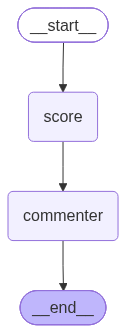

In [ ]:
final_graph

In [ ]:
res = final_graph.invoke({})

InvalidUpdateError: Expected dict, got <function score at 0x000001D2A7595080>
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/INVALID_GRAPH_NODE_RETURN_VALUE

In [ ]:
res

3.  add_messages reducer - for chat history

In [ ]:
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, AIMessage
from typing import Annotated


def custom_reducer(existing: list, new:list):
    all_msg = existing + new

    return all_msg



def isPositive(existing:int, new:int):
    if new < 0:
        return 0
    return new


class ChatState(BaseModel):
    messages : Annotated[list, custom_reducer] = []
    count : Annotated[int, isPositive] = 0



def chat_bot(state:ChatState):
    state.messages = [llm.invoke(state.messages)]
    state.count = -10
    return state



graph = StateGraph(ChatState)
graph.add_node("chat_bot", chat_bot)
graph.add_edge(START, "chat_bot")
graph.add_edge("chat_bot", END)

final = graph.compile()






In [ ]:
final

In [ ]:
res = final.invoke({"messages" : [HumanMessage(content= "Hello, Hows you?")]})

In [ ]:
res